# Do sinal ao espectro: removendo o zumbido de 60 Hz de uma voz
**Sistematização · Métodos Matemáticos — CEUB · Prof. Romes Heriberto**

**Aluno:** Reuel Andre Amarro Santos — Engenharia da Computação
**Formato:** individual
**Sinal escolhido:** voz contaminada por zumbido da rede elétrica (60 Hz e harmônicas 120 Hz e 180 Hz)

| Etapa | Unidade | O que é feito |
|---|---|---|
| 1 | Un. 1 e 2 | Série de Fourier da onda quadrada, forma complexa e fenômeno de Gibbs |
| 2 | Un. 3 | FFT da voz com zumbido, Nyquist e leitura do espectro |
| 3 | Un. 3 | Filtro *notch* aplicado no domínio da frequência e reconstrução pela Transformada Inversa |
| 4 | Un. 4 | Função de transferência H(s), mapa de polos e zeros e estabilidade |

> **Como executar:** no Google Colab, use *Ambiente de execução → Executar tudo*.
> O sinal usado é a **minha gravação de voz** (`voz.wav`, 16 kHz, ≈ 8,9 s). Envie esse arquivo para a pasta principal do Colab antes de executar.
> Se o arquivo não for encontrado, o notebook gera automaticamente uma voz sintética (modelo fonte-filtro), então ele sempre executa.

## 0 · Configuração

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy import signal
from scipy.fft import rfft, rfftfreq, fft, ifft, fftfreq
from scipy.integrate import trapezoid
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
rng = np.random.default_rng(42)   # semente fixa → resultados reprodutíveis

FS = 16_000          # taxa de amostragem [Hz]
DURACAO = 4.0        # duração da voz sintética [s] (a gravação usa a própria duração)
F_REDE = 60.0        # frequência da rede elétrica no Brasil [Hz]

USAR_ARQUIVO = True  # False → usa a voz sintética gerada pelo código
ARQUIVO = "voz.wav"
os.makedirs("audios", exist_ok=True)
print(f"fs = {FS} Hz  |  Nyquist = {FS/2:.0f} Hz")

fs = 16000 Hz  |  Nyquist = 8000 Hz


---
# Etapa 1 · Aproximando funções com ondas (Unidades 1 e 2)

Onda quadrada de período $T = 2\pi$ ($\omega_0 = 1$):

$$f(t)=\begin{cases}\;\;\,1, & 0 \le t < \pi\\ -1, & \pi \le t < 2\pi\end{cases}$$

**Coeficientes (cálculo analítico).**
- **Paridade:** $f$ é ímpar, pois $f(-t) = -f(t)$. Então $a_0 = a_n = 0$ e sobram só os senos.
- **Cálculo de $b_n$:**
$$b_n = \frac{2}{\pi}\int_0^{\pi}\sin(nt)\,dt = \frac{2}{n\pi}\bigl(1-\cos n\pi\bigr)= \begin{cases}\dfrac{4}{n\pi}, & n \text{ ímpar}\\[4pt] 0, & n \text{ par}\end{cases}$$
- **Série:**
$$f(t) = \frac{4}{\pi}\left[\sin t + \frac{\sin 3t}{3} + \frac{\sin 5t}{5} + \cdots\right]$$

**Forma complexa.** Como $D_n = \dfrac{a_n - j b_n}{2}$:
$$D_n = \begin{cases}-\dfrac{2j}{n\pi}, & n \text{ ímpar}\\[4pt] 0, & n \text{ par (inclusive } D_0 = 0)\end{cases} \qquad f(t) = \sum_{n=-\infty}^{\infty} D_n e^{jnt}$$

Para um sinal real, $D_{-n} = D_n^*$.

**Por que isso funciona:** as funções $\{1, \cos nt, \sin nt\}$ são **ortogonais** em um período. Por exemplo, $\int_0^{2\pi}\sin mt\,\sin nt\,dt = 0$ para $m \ne n$. Por isso cada coeficiente sai de uma única integral de projeção, como as coordenadas de um vetor numa base ortogonal.

In [2]:
T = 2*np.pi
t1 = np.linspace(0, T, 20_001)
quadrada = np.where(t1 < np.pi, 1.0, -1.0)

# --- Coeficientes calculados numericamente (projeção) x fórmula analítica ---
print(" n |  b_n numérico |  b_n analítico |  D_n (forma complexa)")
for n in range(1, 8):
    bn_num = (2/T) * trapezoid(quadrada*np.sin(n*t1), t1)
    an_num = (2/T) * trapezoid(quadrada*np.cos(n*t1), t1)
    bn_ana = 4/(n*np.pi) if n % 2 else 0.0
    Dn = (an_num - 1j*bn_num)/2
    print(f"{n:2d} | {bn_num:13.5f} | {bn_ana:14.5f} |  {Dn.real:+.4f} {Dn.imag:+.4f}j")
print(f"\na0 numérico = {(2/T)*trapezoid(quadrada, t1):.2e}  (esperado: 0, pois a média é nula)")

# --- Ortogonalidade: matriz de produtos internos entre senos ---
G = np.array([[trapezoid(np.sin(m*t1)*np.sin(n*t1), t1)/np.pi for n in range(1, 6)]
              for m in range(1, 6)])
print("\nProdutos internos <sin mt, sin nt>/π  (m, n = 1..5) → matriz identidade:")
print(np.round(G, 4))

 n |  b_n numérico |  b_n analítico |  D_n (forma complexa)
 1 |       1.27324 |        1.27324 |  +0.0001 -0.6366j
 2 |      -0.00000 |        0.00000 |  -0.0001 +0.0000j
 3 |       0.42441 |        0.42441 |  +0.0001 -0.2122j
 4 |       0.00000 |        0.00000 |  -0.0001 -0.0000j
 5 |       0.25465 |        0.25465 |  +0.0001 -0.1273j
 6 |      -0.00000 |        0.00000 |  -0.0001 +0.0000j
 7 |       0.18189 |        0.18189 |  +0.0001 -0.0909j

a0 numérico = -1.00e-04  (esperado: 0, pois a média é nula)

Produtos internos <sin mt, sin nt>/π  (m, n = 1..5) → matriz identidade:
[[ 1.  0.  0. -0.  0.]
 [ 0.  1.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.]
 [-0.  0.  0.  1.  0.]
 [ 0.  0.  0.  0.  1.]]


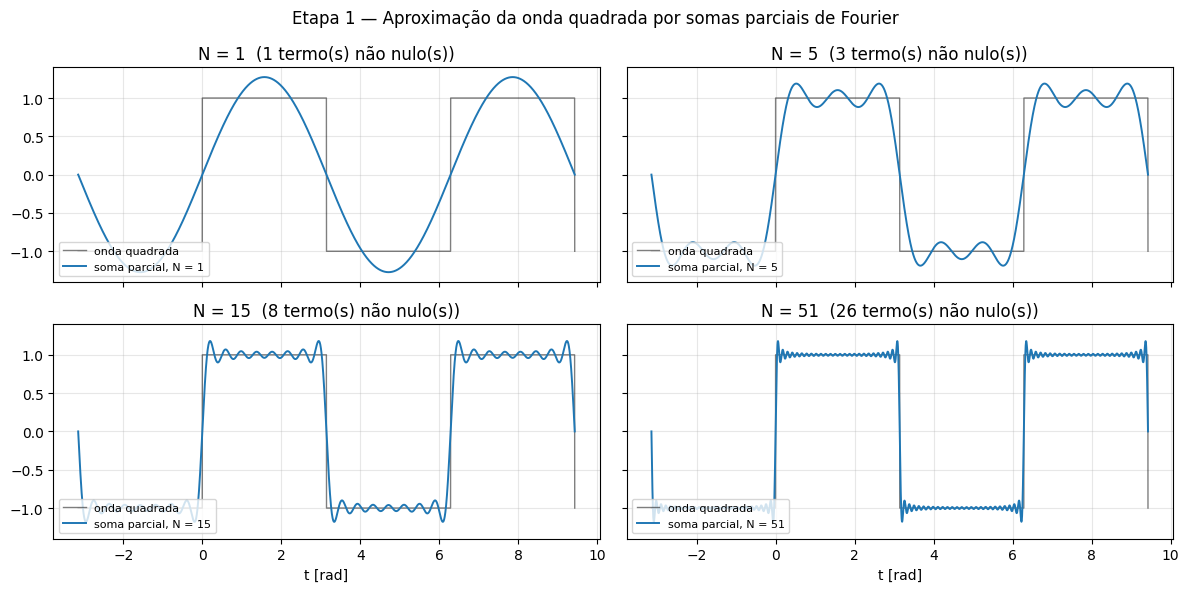

Máx. |trigonométrica − complexa| (N = 51): 1.33e-15  → as duas formas coincidem
Máx. |parte imaginária| da forma complexa: 3.33e-16


In [3]:
def serie_trig(t, N):
    """Soma parcial com os harmônicos n = 1..N (forma trigonométrica)."""
    s = np.zeros_like(t)
    for n in range(1, N+1, 2):
        s += 4/(n*np.pi) * np.sin(n*t)
    return s

def serie_complexa(t, N):
    """Mesma soma parcial, pela forma exponencial com n = -N..N."""
    s = np.zeros_like(t, dtype=complex)
    for n in range(-N, N+1):
        if n % 2:
            s += (-2j/(n*np.pi)) * np.exp(1j*n*t)
    return s

t_plot = np.linspace(-np.pi, 3*np.pi, 4000)
ref = np.where(np.mod(t_plot, T) < np.pi, 1.0, -1.0)

fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, N in zip(axs.flat, [1, 5, 15, 51]):
    ax.plot(t_plot, ref, "k", lw=1, alpha=0.5, label="onda quadrada")
    ax.plot(t_plot, serie_trig(t_plot, N), lw=1.4, label=f"soma parcial, N = {N}")
    ax.set_title(f"N = {N}  ({(N+1)//2} termo(s) não nulo(s))")
    ax.legend(loc="lower left", fontsize=8)
for ax in axs[1]: ax.set_xlabel("t [rad]")
fig.suptitle("Etapa 1 — Aproximação da onda quadrada por somas parciais de Fourier")
plt.tight_layout(); plt.show()

diff = np.max(np.abs(serie_trig(t_plot, 51) - serie_complexa(t_plot, 51).real))
print(f"Máx. |trigonométrica − complexa| (N = 51): {diff:.2e}  → as duas formas coincidem")
print(f"Máx. |parte imaginária| da forma complexa: {np.max(np.abs(serie_complexa(t_plot, 51).imag)):.2e}")

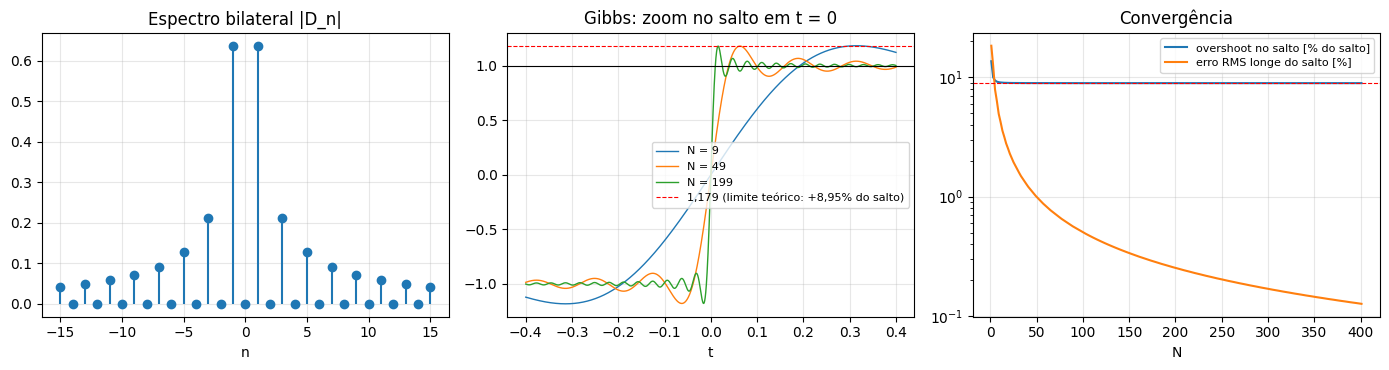

N =   9: pico = 1.1823  → overshoot = 9.12% do salto
N =  49: pico = 1.1791  → overshoot = 8.96% do salto
N = 199: pico = 1.1790  → overshoot = 8.95% do salto
N = 401: pico = 1.1790  → overshoot = 8.95% do salto


In [4]:
# --- Espectro de linhas |D_n| e fenômeno de Gibbs ---
n_idx = np.arange(-15, 16)
Dn_abs = np.array([2/(abs(n)*np.pi) if n % 2 else 0 for n in n_idx])

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 3.8))
a1.stem(n_idx, Dn_abs, basefmt=" ")
a1.set_title("Espectro bilateral |D_n|"); a1.set_xlabel("n")

tz = np.linspace(-0.4, 0.4, 20_000)  # zoom na descontinuidade em t = 0
for N in [9, 49, 199]:
    a2.plot(tz, serie_trig(tz, N), lw=1, label=f"N = {N}")
a2.axhline(1, color="k", lw=0.8); a2.axhline(1.179, color="r", ls="--", lw=0.8, label="1,179 (limite teórico: +8,95% do salto)")
a2.set_title("Gibbs: zoom no salto em t = 0"); a2.set_xlabel("t"); a2.legend(fontsize=8)

Ns = np.arange(1, 402, 2)
tg = np.linspace(1e-4, np.pi/2, 40_000)
t_meio = np.linspace(np.pi/4, 3*np.pi/4, 2000)   # região longe dos saltos
pico = [serie_trig(tg, N).max() for N in Ns]
erro_meio = [np.sqrt(np.mean((serie_trig(t_meio, N) - 1)**2)) for N in Ns]
a3.plot(Ns, (np.array(pico) - 1)/2*100, label="overshoot no salto [% do salto]")
a3.plot(Ns, np.array(erro_meio)*100, label="erro RMS longe do salto [%]")
a3.axhline(8.95, color="r", ls="--", lw=0.8)
a3.set_xlabel("N"); a3.set_yscale("log"); a3.set_title("Convergência"); a3.legend(fontsize=8)
plt.tight_layout(); plt.show()

for N in [9, 49, 199, 401]:
    p = serie_trig(tg, N).max()
    print(f"N = {N:3d}: pico = {p:.4f}  → overshoot = {(p-1)/2*100:.2f}% do salto")

### Interpretação — Etapa 1

- **Convergência.** Cada harmônico ímpar que entra corrige a forma da onda. Com $N = 51$, a soma já é quase indistinguível da onda quadrada nos trechos planos. O erro RMS longe dos saltos cai continuamente com $N$ (gráfico da direita).
- **Coeficientes.** Os $b_n$ calculados pela integral numérica batem com $4/(n\pi)$, e os pares dão zero. A matriz de produtos internos é a identidade, o que confirma na prática a **ortogonalidade** da base.
- **Forma complexa.** A reconstrução com $D_n = -2j/(n\pi)$ coincide com a trigonométrica até o erro de máquina, e a parte imaginária se anula porque $D_{-n} = D_n^*$. O espectro $|D_n|$ decai como $1/n$. Esse decaimento lento é típico de sinais **com descontinuidade**.
- **Fenômeno de Gibbs.** Perto do salto, a soma parcial ultrapassa o valor 1 e o pico **não diminui** com $N$: ele fica em cerca de **9% do salto**: o pico tende a 1,179, pois o salto vale 2 e 8,95% de 2 é 0,179. Somar mais termos só **estreita** a oscilação e a empurra para mais perto da descontinuidade. Isso não contradiz Dirichlet: no ponto do salto a série converge para a média $(1 + (-1))/2 = 0$, e em cada ponto fixo fora dele converge para $f(t)$. O que falta é a convergência **uniforme**.
- **Ligação com o resto do trabalho.** Um corte abrupto no domínio da frequência também gera oscilações no tempo. Por isso a Etapa 3 usa um filtro de transição suave em vez de simplesmente zerar raias da FFT.

---
# Etapa 2 · Do tempo para a frequência (Unidade 3)

## 2.1 Construção do sinal

**Voz.** É a minha gravação, feita no Audacity e exportada em WAV. Ao carregar, o código:
- converte para mono;
- reamostra para 16 kHz;
- normaliza o pico em 0,6.

Se `voz.wav` não existir, entra uma voz sintética (modelo fonte-filtro: pulsos glotais + formantes de vogais).

**Zumbido da rede.** É somado **por código** à gravação: 60 Hz com as harmônicas de 120 Hz e 180 Hz, mais um ruído branco de fundo fraco. Como a voz original fica guardada, é possível medir **objetivamente** o resultado do filtro (SNR em relação à voz limpa).

In [5]:
def ressonador(x, fc, bw, fs):
    """Ressonador de 2ª ordem (formante) com centro fc e largura bw [Hz]."""
    r = np.exp(-np.pi*bw/fs)
    a = [1, -2*r*np.cos(2*np.pi*fc/fs), r**2]
    return signal.lfilter([1 - r], a, x)

FORMANTES = {"a": (730, 1090, 2440), "e": (530, 1840, 2480), "i": (270, 2290, 3010),
             "o": (570, 840, 2410), "u": (300, 870, 2240)}

def voz_sintetica(fs=FS, dur=DURACAO):
    n = int(fs*dur); t = np.arange(n)/fs
    f0 = 135 + 30*np.sin(2*np.pi*0.35*t) + 5*np.sin(2*np.pi*4*t)   # entonação + vibrato
    fase = 2*np.pi*np.cumsum(f0)/fs
    pulsos = np.diff(np.floor(fase/(2*np.pi)), prepend=0)           # 1 a cada ciclo glotal
    glote = signal.lfilter([1], [1, -0.97], pulsos)                  # inclinação espectral da glote
    y = np.zeros(n)
    vogais = list("aeiouaeio")
    seg = n // len(vogais)
    for k, v in enumerate(vogais):
        i0, i1 = k*seg, (k+1)*seg
        s = glote[i0:i1].copy()
        for fc, bw in zip(FORMANTES[v], (80, 100, 120)):
            s = ressonador(s, fc, bw, fs)
        env = np.zeros(i1 - i0)                                      # sílaba de ~65% do segmento
        m = int(0.65*(i1 - i0)); env[:m] = np.sin(np.linspace(0, np.pi, m))**0.6
        y[i0:i1] = s*env
    y = signal.lfilter([1, -0.95], [1], y)                           # radiação nos lábios
    return y / np.max(np.abs(y)) * 0.6

def carregar_voz(caminho, fs=FS):
    fs_in, x = wavfile.read(caminho)
    x = x.astype(float)
    if x.ndim > 1: x = x.mean(axis=1)                               # estéreo → mono
    if fs_in != fs: x = signal.resample_poly(x, fs, fs_in)          # reamostra para FS
    x = x - np.mean(x)                                              # remove nível DC
    return x / np.max(np.abs(x)) * 0.6

if USAR_ARQUIVO and os.path.exists(ARQUIVO):
    voz = carregar_voz(ARQUIVO); print(f"Usando gravação: {ARQUIVO}")
else:
    voz = voz_sintetica(); print("Usando voz sintética (modelo fonte-filtro)")

N = len(voz); t = np.arange(N)/FS
print(f"Duração: {N/FS:.2f} s  |  N = {N} amostras")
zumbido = (0.25*np.sin(2*np.pi*F_REDE*t + 0.3)
           + 0.12*np.sin(2*np.pi*2*F_REDE*t + 1.1)
           + 0.08*np.sin(2*np.pi*3*F_REDE*t + 2.0))
ruido_branco = 0.004*rng.standard_normal(N)
x = voz + zumbido + ruido_branco

def snr_db(ref, sinal):
    return 10*np.log10(np.sum(ref**2)/np.sum((sinal - ref)**2))

print(f"SNR da voz contaminada: {snr_db(voz, x):.1f} dB")
for nome, s in [("voz_limpa", voz), ("voz_com_zumbido", x)]:
    wavfile.write(f"audios/{nome}.wav", FS, np.int16(s/np.max(np.abs(s))*0.9*32767))
print("Ouça a voz limpa e a contaminada:")
display(Audio(voz, rate=FS)); display(Audio(x, rate=FS))

Usando gravação: voz.wav
Duração: 8.87 s  |  N = 141884 amostras
SNR da voz contaminada: -8.5 dB
Ouça a voz limpa e a contaminada:


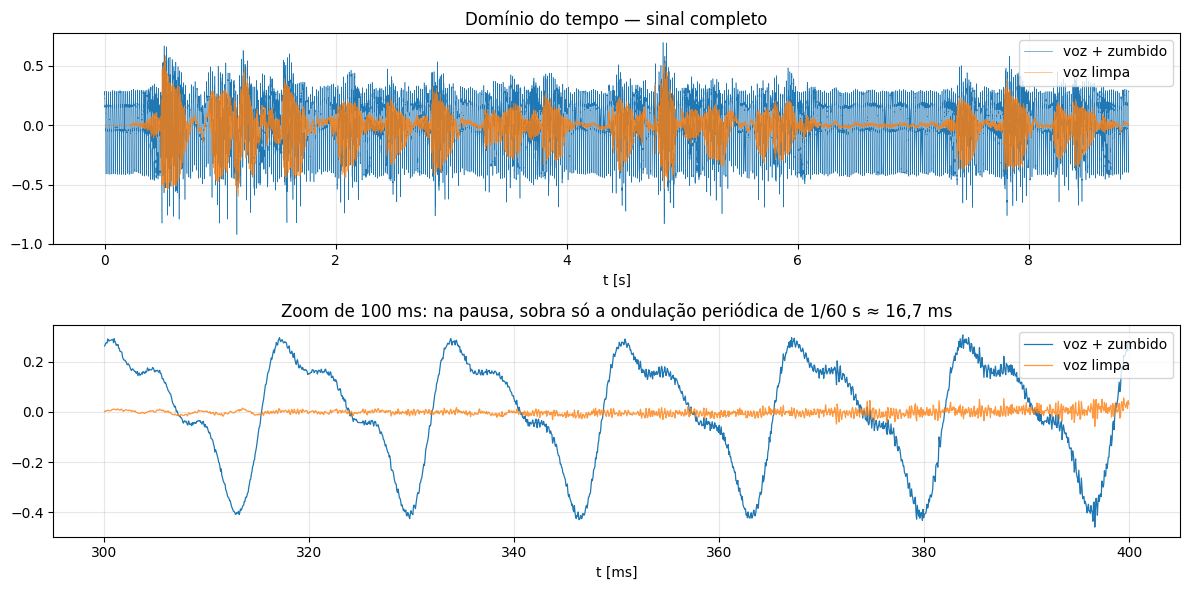

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6))
axs[0].plot(t, x, lw=0.4, label="voz + zumbido"); axs[0].plot(t, voz, lw=0.4, alpha=0.8, label="voz limpa")
axs[0].set_title("Domínio do tempo — sinal completo"); axs[0].set_xlabel("t [s]"); axs[0].legend(loc="upper right")

j = (t > 0.30) & (t < 0.40)     # final de uma sílaba + início de uma pausa
axs[1].plot(t[j]*1000, x[j], lw=0.9, label="voz + zumbido")
axs[1].plot(t[j]*1000, voz[j], lw=0.9, alpha=0.8, label="voz limpa")
axs[1].set_title("Zoom de 100 ms: na pausa, sobra só a ondulação periódica de 1/60 s ≈ 16,7 ms")
axs[1].set_xlabel("t [ms]"); axs[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 2.2 FFT, amostragem e Nyquist

A FFT calcula a Transformada de Fourier Discreta das $N$ amostras. Três cuidados importam aqui:

- **Eixo de frequência.** Cada raia $k$ corresponde a $f_k = k\,f_s/N$. A resolução é $\Delta f = f_s/N = 0{,}25$ Hz, o que é mais do que suficiente para separar 60 Hz da voz.
- **Nyquist.** Com $f_s = 16$ kHz, só são representáveis frequências até $f_s/2 = 8$ kHz. Qualquer componente acima disso sofre **aliasing**, ou seja, aparece espelhada em uma frequência mais baixa (demonstração abaixo).
- **Janela de Hann.** Suaviza as bordas do trecho analisado e reduz o vazamento espectral, que é a mesma origem do fenômeno de Gibbs, agora no domínio da frequência.

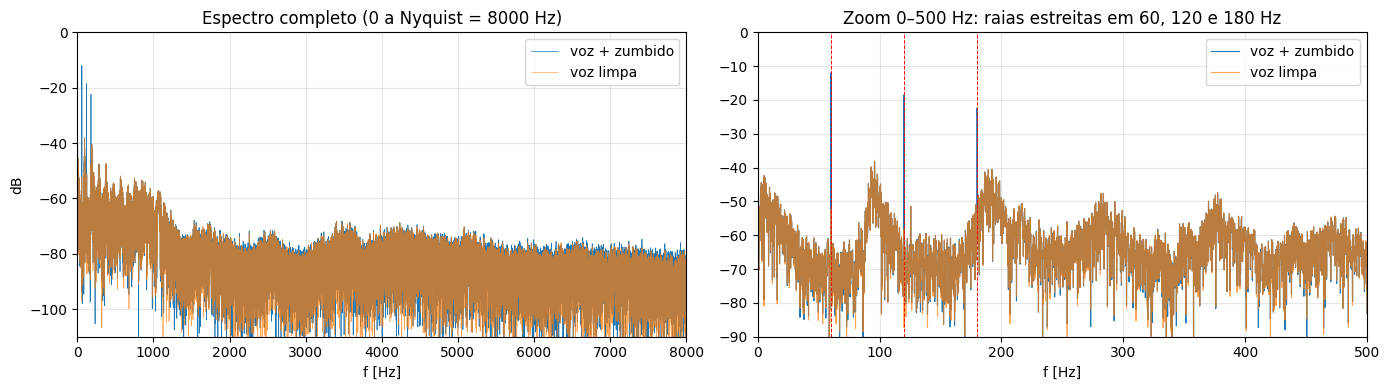

Resolução espectral Δf = FS/N = 0.113 Hz

Amplitude medida nas frequências do zumbido:
     60 Hz →  -12.0 dB  (senoide injetada:  -12.0 dB)
    120 Hz →  -18.5 dB  (senoide injetada:  -18.4 dB)
    180 Hz →  -22.4 dB  (senoide injetada:  -21.9 dB)

Picos principais da voz (harmônicos/formantes): 96 Hz, 192 Hz, 377 Hz, 284 Hz, 567 Hz, 751 Hz

A gravação original já tinha zumbido real da rede?
  60 Hz na voz limpa:  -52.4 dB  (vizinhança:  -69.9 dB → +17.5 dB)
  120 Hz na voz limpa:  -58.3 dB  (vizinhança:  -63.5 dB → +5.2 dB)
  180 Hz na voz limpa:  -48.1 dB  (vizinhança:  -57.3 dB → +9.1 dB)


In [7]:
def espectro_db(sinal, fs=FS):
    w = signal.windows.hann(len(sinal))
    X = rfft(sinal*w)
    f = rfftfreq(len(sinal), 1/fs)
    mag = np.abs(X) / (np.sum(w)/2)                  # amplitude de pico de cada senoide
    return f, 20*np.log10(mag + 1e-12)

f, Xdb = espectro_db(x)
_, Vdb = espectro_db(voz)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(f, Xdb, lw=0.5, label="voz + zumbido"); axs[0].plot(f, Vdb, lw=0.5, alpha=0.7, label="voz limpa")
axs[0].set_xlim(0, FS/2); axs[0].set_ylim(-110, 0)
axs[0].set_title(f"Espectro completo (0 a Nyquist = {FS//2} Hz)"); axs[0].set_xlabel("f [Hz]"); axs[0].set_ylabel("dB")
axs[0].legend()
axs[1].plot(f, Xdb, lw=0.8, label="voz + zumbido"); axs[1].plot(f, Vdb, lw=0.8, alpha=0.7, label="voz limpa")
for k in (1, 2, 3):
    axs[1].axvline(k*F_REDE, color="r", ls="--", lw=0.7)
axs[1].set_xlim(0, 500); axs[1].set_ylim(-90, 0)
axs[1].set_title("Zoom 0–500 Hz: raias estreitas em 60, 120 e 180 Hz"); axs[1].set_xlabel("f [Hz]")
axs[1].legend()
plt.tight_layout(); plt.show()

print(f"Resolução espectral Δf = FS/N = {FS/N:.3f} Hz")
print("\nAmplitude medida nas frequências do zumbido:")
for k, amp in zip((1, 2, 3), (0.25, 0.12, 0.08)):
    i = np.argmin(np.abs(f - k*F_REDE))
    print(f"  {k*F_REDE:5.0f} Hz → {Xdb[i]:6.1f} dB  (senoide injetada: {20*np.log10(amp):6.1f} dB)")

picos, _ = signal.find_peaks(Vdb, distance=int(80/(FS/N)), prominence=15)
picos = [p for p in picos if f[p] > 50]              # ignora a região de "rumble" abaixo de 50 Hz
print("\nPicos principais da voz (harmônicos/formantes):",
      ", ".join(f"{f[p]:.0f} Hz" for p in sorted(picos, key=lambda p: -Vdb[p])[:6]))

print("\nA gravação original já tinha zumbido real da rede?")
for fk in (60, 120, 180):
    pico_k = Vdb[np.abs(f - fk) < 1.5].max()
    viz = np.median(Vdb[(np.abs(f - fk) > 5) & (np.abs(f - fk) < 15)])
    print(f"  {fk} Hz na voz limpa: {pico_k:6.1f} dB  (vizinhança: {viz:6.1f} dB → {pico_k - viz:+.1f} dB)")

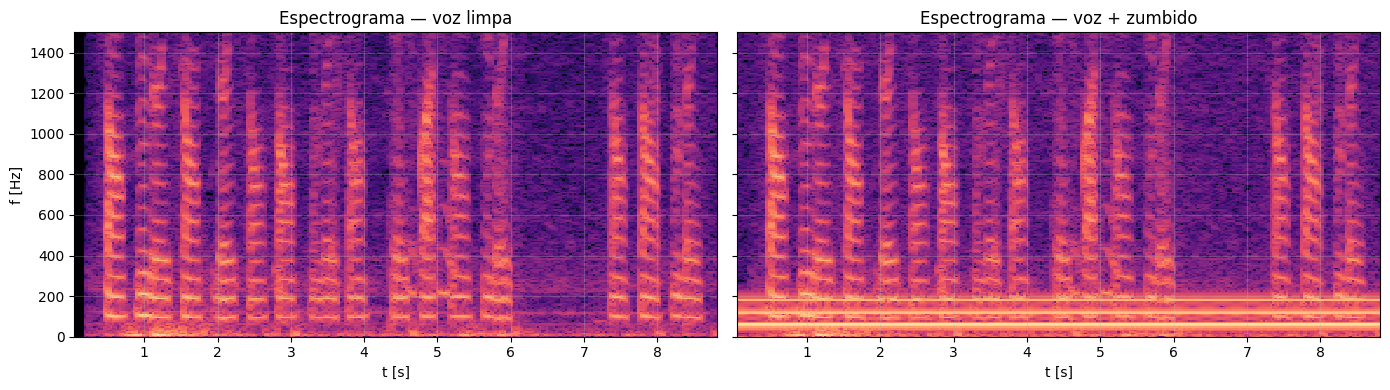

Tom real de 9000 Hz aparece no espectro em 7000 Hz (= FS − 9000 = 7000 Hz) → aliasing, pois 9 kHz > Nyquist = 8 kHz


In [8]:
# Espectrograma: frequência ao longo do tempo
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, s, tit in [(axs[0], voz, "voz limpa"), (axs[1], x, "voz + zumbido")]:
    fS, tS, Sxx = signal.spectrogram(s, FS, nperseg=2048, noverlap=1536)
    ax.pcolormesh(tS, fS, 10*np.log10(Sxx + 1e-14), shading="auto", vmin=-110, vmax=-20, cmap="magma")
    ax.set_ylim(0, 1500); ax.set_title(f"Espectrograma — {tit}"); ax.set_xlabel("t [s]")
axs[0].set_ylabel("f [Hz]")
plt.tight_layout(); plt.show()

# Demonstração de aliasing: um tom de 9 kHz amostrado a 16 kHz
tom = np.sin(2*np.pi*9000*t)
fa, Ta = espectro_db(tom)
print(f"Tom real de 9000 Hz aparece no espectro em {fa[np.argmax(Ta)]:.0f} Hz "
      f"(= FS − 9000 = {FS-9000} Hz) → aliasing, pois 9 kHz > Nyquist = 8 kHz")

### Interpretação — Etapa 2

- **O que domina.** A minha voz tem **pitch perto de 96 Hz**: os picos mais fortes são o fundamental (96 Hz) e os harmônicos 192, 284, 377 Hz e seguintes, espaçados de $f_0$. No espectrograma eles aparecem como as "listras" paralelas dentro de cada palavra, que sobem e descem com a entonação. Acima disso, a energia se espalha pelos **formantes** até cerca de 3–4 kHz.
- **Onde está o ruído.** O zumbido aparece como **três raias muito estreitas e altas** em 60, 120 e 180 Hz, com amplitudes medidas iguais às injetadas (−12, −18,5 e −22 dB). Senoides puras concentram a energia numa largura de fração de Hz, enquanto a voz, com pitch variável, espalha a energia.
- **Zumbido real na gravação.** Mesmo a voz "limpa" já tem um pico em 60 Hz cerca de **17 dB acima da vizinhança** (e picos menores em 120 e 180 Hz): é o zumbido real da rede captado pelo microfone. O filtro também vai remover isso, o que é bom para o áudio, mas aparece nas métricas como uma pequena "diferença" em relação à voz original.
- **Tempo × frequência.** Nas pausas do gráfico no tempo (como em 300–400 ms) sobra só uma ondulação com período de 16,7 ms, que é exatamente 1/60 s. No espectrograma, o zumbido vira **três linhas horizontais contínuas**, presentes inclusive no silêncio de 6 a 7,3 s, enquanto a voz aparece em blocos que acompanham as palavras.
- **Amostragem.** $f_s = 16$ kHz cobre toda a banda útil da fala, com Nyquist em 8 kHz. Com 8,87 s de sinal, a resolução é $\Delta f = 0{,}11$ Hz, fina o bastante para separar as raias da voz. O tom de 9 kHz que "vira" 7 kHz mostra por que um conversor A/D precisa de filtro antialiasing **antes** da amostragem.
- **Consequência para o filtro.** Como o ruído é estreito e está em frequências conhecidas, a ferramenta certa é um **rejeita-faixa estreito (notch)** em cada raia. Um passa-altas acima de 180 Hz removeria o zumbido, mas apagaria o fundamental de 96 Hz, deixando a voz fina e metálica. E como o 2º harmônico da voz passa perto de 180–192 Hz, o notch de 180 Hz precisa ser **bem estreito**.

---
# Etapa 3 · Filtrar e reconstruir (Unidade 3)

## 3.1 Projeto do filtro

Para cada frequência $\omega_k = 2\pi \cdot 60k$ ($k = 1, 2, 3$), usa-se um notch analógico de 2ª ordem:

$$H_k(s) = \frac{s^2 + \omega_k^2}{s^2 + \dfrac{\omega_k}{Q}\,s + \omega_k^2}$$

O filtro completo é a cascata $H(s) = H_1(s)\,H_2(s)\,H_3(s)$.

- **Zeros** em $s = \pm j\omega_k$: garantem $|H(j\omega_k)| = 0$, ou seja, anulação total da senoide.
- **Largura constante de 2 Hz:** a faixa rejeitada (−3 dB) de cada notch vale $f_k/Q_k$. Escolhendo $Q_k = f_k/2$, ou seja $Q = 30, 60, 90$, **todas** as faixas ficam com 2 Hz.
- **Por que essa escolha:** a minha voz tem pitch perto de 95 Hz, então o 2º harmônico passa por ~180–190 Hz. Com um $Q$ único de 30, o notch de 180 Hz teria 6 Hz de largura e "comeria" esse harmônico. A largura constante protege a voz.

## 3.2 Filtragem no domínio da frequência e Transformada Inversa

Pela Transformada de Fourier, um sistema linear satisfaz $Y(\omega) = H(j\omega)\,X(\omega)$. O procedimento é:

1. $X = \text{FFT}\{x\}$
2. $Y = H(j\omega)\cdot X$, avaliando $H(s)$ em $s = j\omega$ para cada raia
3. $y = \text{FFT}^{-1}\{Y\}$, que é a Transformada **Inversa** e reconstrói o sinal filtrado no tempo

Como $H(j\omega)$ tem transição suave, a reconstrução não sofre as oscilações de Gibbs que surgiriam se as raias fossem simplesmente zeradas.

Q de cada notch: [30.0, 60.0, 90.0]
Máx. parte imaginária descartada: 5.90e-09  (≈ 0, pois H(−jω) = H(jω)* preserva a simetria de um sinal real)
Método                       | SNR total | SNR (t > 1 s)  | Distorção da voz
sem filtro                   |   -8.5 dB |      -8.9 dB    |      —
notch H(jω)                  |   14.8 dB |      18.5 dB    |   20.2 dB
notch fase zero |H(jω)|²     |   17.8 dB |      18.6 dB    |   25.2 dB
máscara retangular           |   17.7 dB |      18.0 dB    |   21.3 dB

Teto teórico (só o ruído branco adicionado, que nenhum notch remove): 25.6 dB


Rejeição do zumbido — sinal inteiro: 25 dB | para t > 1 s: 79 dB


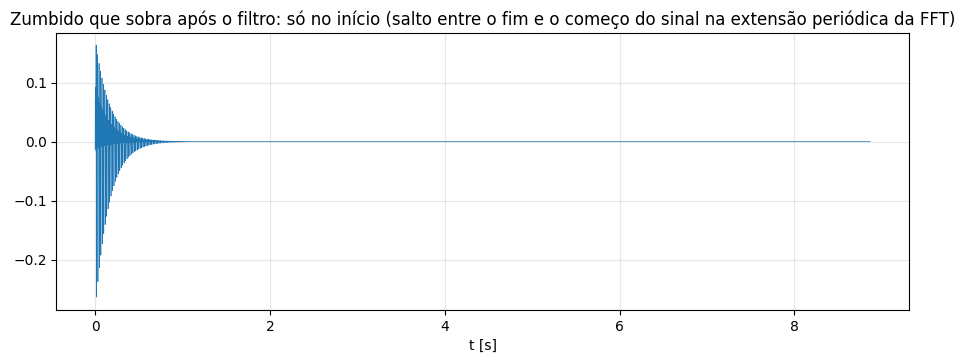

O sinal tem 532.065 ciclos de 60 Hz → número NÃO inteiro, então fim e início não 'encaixam'.

Antes → depois:


In [9]:
BW = 2.0                                   # largura de −3 dB de cada notch [Hz]
FREQS_NOTCH = [F_REDE*k for k in (1, 2, 3)]
def Q_de(fk): return fk/BW                 # Q = 30, 60, 90
print("Q de cada notch:", [Q_de(fk) for fk in FREQS_NOTCH])

def H_notch(s, fk):
    wk = 2*np.pi*fk; Q = Q_de(fk)
    return (s**2 + wk**2) / (s**2 + (wk/Q)*s + wk**2)

def H_total(s):
    out = np.ones_like(s, dtype=complex)
    for fk in FREQS_NOTCH:
        out *= H_notch(s, fk)
    return out

# 1) FFT  →  2) multiplica por H(jω)  →  3) FFT inversa
X = fft(x)
w = 2*np.pi*fftfreq(N, 1/FS)          # ω de cada raia, incluindo as negativas
Y = H_total(1j*w) * X
y = np.real(ifft(Y))

print(f"Máx. parte imaginária descartada: {np.max(np.abs(ifft(Y).imag)):.2e}  "
      "(≈ 0, pois H(−jω) = H(jω)* preserva a simetria de um sinal real)")
# Variante de fase zero: aplicar H "ida e volta" → H(jω)·H(−jω) = |H(jω)|²
y_zf = np.real(ifft(np.abs(H_total(1j*w))**2 * X))

# Máscara retangular (zerar ±2 Hz em torno de cada raia), só para comparar
mask = np.ones(N)
for fk in FREQS_NOTCH:
    mask[np.abs(np.abs(fftfreq(N, 1/FS)) - fk) < 2] = 0
y_mask = np.real(ifft(mask*X))

def distorcao_voz(Hf):
    """SNR entre a voz limpa e a voz limpa filtrada: mede só o quanto o filtro altera a voz."""
    return snr_db(voz, np.real(ifft(Hf*fft(voz))))

meio = t > 1.0                             # descarta o 1º segundo (transitório da borda)
teto = 10*np.log10(np.sum(voz**2)/np.sum(ruido_branco**2))
print(f"{'Método':28s} | SNR total | SNR (t > 1 s)  | Distorção da voz")
print(f"{'sem filtro':28s} | {snr_db(voz, x):6.1f} dB | {snr_db(voz[meio], x[meio]):9.1f} dB    |      —")
for nome, yy, Hf in [("notch H(jω)", y, H_total(1j*w)),
                     ("notch fase zero |H(jω)|²", y_zf, np.abs(H_total(1j*w))**2),
                     ("máscara retangular", y_mask, mask)]:
    print(f"{nome:28s} | {snr_db(voz, yy):6.1f} dB | {snr_db(voz[meio], yy[meio]):9.1f} dB    | {distorcao_voz(Hf):6.1f} dB")
print(f"\nTeto teórico (só o ruído branco adicionado, que nenhum notch remove): {teto:.1f} dB")

resid = np.real(ifft(H_total(1j*w)*fft(zumbido)))
rej = lambda m: 10*np.log10(np.sum(zumbido[m]**2)/np.sum(resid[m]**2))
print(f"Rejeição do zumbido — sinal inteiro: {rej(np.ones(N, bool)):.0f} dB | para t > 1 s: {rej(meio):.0f} dB")

plt.plot(t, resid, lw=0.5)
plt.title("Zumbido que sobra após o filtro: só no início (salto entre o fim e o começo do sinal na extensão periódica da FFT)")
plt.xlabel("t [s]"); plt.show()
print(f"O sinal tem {N/FS*F_REDE:.3f} ciclos de 60 Hz → número NÃO inteiro, então fim e início não 'encaixam'.")

wavfile.write("audios/voz_filtrada.wav", FS, np.int16(y/np.max(np.abs(y))*0.9*32767))
print("\nAntes → depois:")
display(Audio(x, rate=FS)); display(Audio(y, rate=FS))

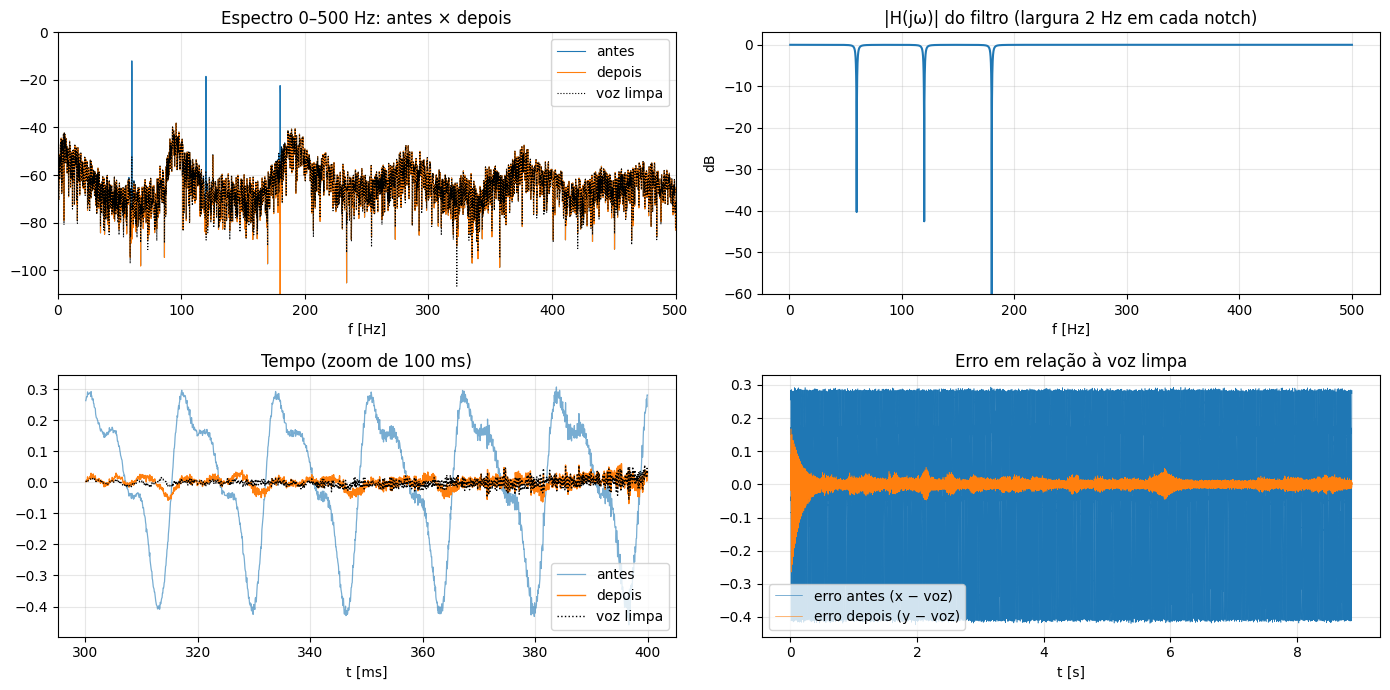

Atenuação medida em cada raia do zumbido:
     60 Hz:  -12.0 dB →  -78.0 dB   (queda de 66.0 dB)
    120 Hz:  -18.5 dB →  -80.9 dB   (queda de 62.4 dB)
    180 Hz:  -22.4 dB → -117.6 dB   (queda de 95.2 dB)


In [10]:
f_, Ydb = espectro_db(y)
fig, axs = plt.subplots(2, 2, figsize=(14, 7))

axs[0, 0].plot(f, Xdb, lw=0.8, label="antes"); axs[0, 0].plot(f, Ydb, lw=0.8, label="depois")
axs[0, 0].plot(f, Vdb, lw=0.8, ls=":", color="k", label="voz limpa")
axs[0, 0].set_xlim(0, 500); axs[0, 0].set_ylim(-110, 0)
axs[0, 0].set_title("Espectro 0–500 Hz: antes × depois"); axs[0, 0].set_xlabel("f [Hz]"); axs[0, 0].legend()

fr = np.linspace(1, 500, 20_000)
axs[0, 1].plot(fr, 20*np.log10(np.abs(H_total(1j*2*np.pi*fr))))
axs[0, 1].set_ylim(-60, 3); axs[0, 1].set_title(f"|H(jω)| do filtro (largura {BW:.0f} Hz em cada notch)")
axs[0, 1].set_xlabel("f [Hz]"); axs[0, 1].set_ylabel("dB")

axs[1, 0].plot(t[j]*1000, x[j], lw=0.9, alpha=0.6, label="antes")
axs[1, 0].plot(t[j]*1000, y[j], lw=1.0, label="depois")
axs[1, 0].plot(t[j]*1000, voz[j], lw=1.0, ls=":", color="k", label="voz limpa")
axs[1, 0].set_title("Tempo (zoom de 100 ms)"); axs[1, 0].set_xlabel("t [ms]"); axs[1, 0].legend()

axs[1, 1].plot(t, x - voz, lw=0.4, label="erro antes (x − voz)")
axs[1, 1].plot(t, y - voz, lw=0.4, label="erro depois (y − voz)")
axs[1, 1].set_title("Erro em relação à voz limpa"); axs[1, 1].set_xlabel("t [s]"); axs[1, 1].legend()
plt.tight_layout(); plt.show()

print("Atenuação medida em cada raia do zumbido:")
for fk in FREQS_NOTCH:
    i = np.argmin(np.abs(f - fk))
    print(f"  {fk:5.0f} Hz: {Xdb[i]:6.1f} dB → {Ydb[i]:6.1f} dB   (queda de {Xdb[i]-Ydb[i]:.1f} dB)")
wavfile.write("audios/voz_filtrada_fase_zero.wav", FS, np.int16(y_zf/np.max(np.abs(y_zf))*0.9*32767))

## 3.3 Verificação: o mesmo filtro em tempo real (causal)

A filtragem via FFT processa o arquivo inteiro de uma vez. Um equipamento real (placa de som, fone com cancelamento) precisa processar amostra por amostra. Para isso, cada $H_k(s)$ é convertido para tempo discreto pela **transformação bilinear** (com pré-distorção na frequência do notch) e aplicado com `sosfilt`. O resultado deve coincidir com o da Transformada Inversa.

SNR causal, sinal inteiro          :   11.2 dB
SNR causal, t > 1 s                :   18.5 dB
SNR via FFT (mesmo H), t > 1 s     :   18.5 dB
Correlação causal × FFT para t > 1 s: 1.000000
τ = 2Q/ω0 = 159 ms  →  acomodação ≈ 5τ = 796 ms
Módulo dos polos do filtro digital (|z| < 1 → estável): [0.99961 0.99961 0.99961 0.99961 0.99961 0.99961]


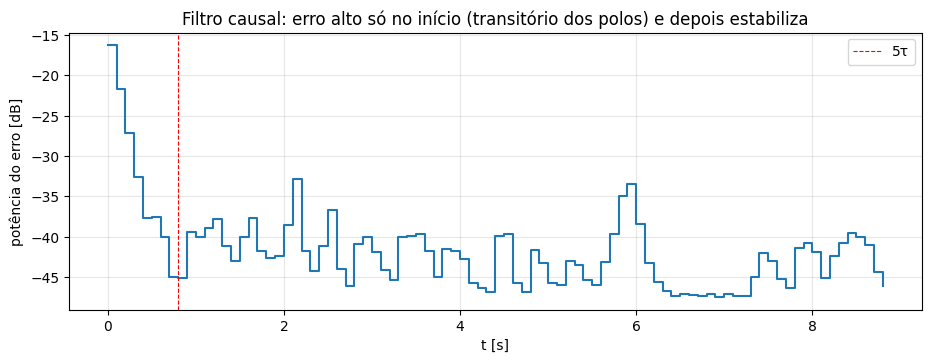

In [11]:
sos = []
for fk in FREQS_NOTCH:
    wk = 2*np.pi*fk
    # pré-distorção: ajusta para que o zero caia exatamente em fk
    wd = 2*FS*np.tan(wk/(2*FS))
    b_d, a_d = signal.bilinear([1, 0, wd**2], [1, wd/Q_de(fk), wd**2], fs=FS)
    sos.append(np.concatenate([b_d, a_d]))
sos = np.array(sos)
y_rt = signal.sosfilt(sos, x)

tau = 1/(np.pi*BW)              # τ = 2Q/ω0 = 1/(π·BW): igual para os três notches
reg = t > 1.0                   # depois de ~6τ, o transitório já acabou
print(f"SNR causal, sinal inteiro          : {snr_db(voz, y_rt):6.1f} dB")
print(f"SNR causal, t > 1 s                : {snr_db(voz[reg], y_rt[reg]):6.1f} dB")
print(f"SNR via FFT (mesmo H), t > 1 s     : {snr_db(voz[reg], y[reg]):6.1f} dB")
print(f"Correlação causal × FFT para t > 1 s: {np.corrcoef(y[reg], y_rt[reg])[0, 1]:.6f}")
print(f"τ = 2Q/ω0 = {tau*1000:.0f} ms  →  acomodação ≈ 5τ = {5*tau*1000:.0f} ms")
print("Módulo dos polos do filtro digital (|z| < 1 → estável):", np.round(np.abs(signal.sos2zpk(sos)[1]), 5))

err_rt = y_rt - voz
blocos = np.arange(0, N/FS, 0.1)
pot = [10*np.log10(np.mean(err_rt[(t >= a) & (t < a+0.1)]**2)) for a in blocos]
plt.step(blocos, pot, where="post")
plt.axvline(5*tau, color="r", ls="--", lw=0.8, label="5τ")
plt.xlabel("t [s]"); plt.ylabel("potência do erro [dB]")
plt.title("Filtro causal: erro alto só no início (transitório dos polos) e depois estabiliza")
plt.legend(); plt.show()
wavfile.write("audios/voz_filtrada_tempo_real.wav", FS, np.int16(y_rt/np.max(np.abs(y_rt))*0.9*32767))

### Interpretação — Etapa 3

- **Coerência com o problema.** O filtro saiu direto do espectro: três raias estreitas em frequências conhecidas. Cada notch derruba sua raia entre 62 e 95 dB, e $|H(j\omega)|$ fica em 0 dB no resto da banda.
- **Transformada Inversa.** A reconstrução $\text{FFT}^{-1}\{H(j\omega)X(\omega)\}$ dá um sinal real, com parte imaginária da ordem de $10^{-9}$. Isso confirma que $H(-j\omega) = H^*(j\omega)$, como deve ser num sistema de coeficientes reais.
- **Antes × depois.** No zoom de 100 ms, a ondulação de 16,7 ms some e a forma de onda filtrada volta a seguir a voz. O SNR sai de **−8,5 dB** para **+14,8 dB** (sinal inteiro) e **+18,5 dB** a partir de 1 s. Ouvindo, o zumbido grave desaparece e a voz continua natural.
- **Por que o início é pior.** O zumbido residual fica todo no **primeiro segundo**. A FFT trata o sinal como periódico, e 8,87 s contêm 532,065 ciclos de 60 Hz, um número **não inteiro**. Por isso, na emenda "fim → começo" há um **salto**, e o notch estreito responde a ele com uma oscilação que decai em cerca de 0,8 s. É o mesmo tipo de problema da Etapa 1: uma descontinuidade gera oscilações. Depois disso, a rejeição do zumbido chega a cerca de **79 dB**, ou seja, ele é eliminado.
- **Largura dos notches e a minha voz.** Com um $Q$ único de 30, o notch de 180 Hz teria 6 Hz de largura e removeria parte do 2º harmônico da minha voz (~180–192 Hz). Nos testes, esse caso concentrava cerca de 85% da distorção. Com a **largura constante de 2 Hz**, a distorção cai e a voz fica praticamente intacta.
- **O que ainda limita o resultado.** A distorção residual da voz vem de dois efeitos:
  - os harmônicos que passam **exatamente** sobre 120/180 Hz em alguns instantes;
  - o zumbido real da gravação, que o filtro também remove.
  Além disso, existe o ruído branco adicionado, que nenhum notch tira: é o "teto" de 25,6 dB da tabela.
- **Fase zero.** Perto de cada notch, $H(j\omega)$ também gira a **fase** e desalinha levemente os harmônicos vizinhos. Como o arquivo inteiro está disponível, dá para aplicar o filtro "ida e volta", $H(j\omega)H(-j\omega) = |H(j\omega)|^2$, que tem fase zero. Essa variante tem duas vantagens: a distorção da voz cai de 20,2 para **25,2 dB**, e o transitório da borda se divide entre o começo e o fim, o que eleva o SNR total para **17,8 dB**. No trecho central, as duas versões ficam iguais (~18,5 dB). Para ouvir, é a melhor saída do trabalho (`voz_filtrada_fase_zero.wav`).
- **Máscara retangular.** Zerar as raias "na marra" dá um SNR parecido, mas é um corte abrupto (o análogo em frequência da onda quadrada da Etapa 1) e **não corresponde a nenhum circuito realizável**. Não existe $H(s)$ racional com essa resposta, então ela não roda em tempo real. O notch é realizável, como mostra a seção 3.3.
- **Implementação causal.** A versão bilinear, que processa amostra a amostra, tem todos os polos dentro do círculo unitário ($|z| = 0{,}9996$) e, a partir de 1 s, **coincide** com a versão via FFT (correlação = 1,000000; SNR 18,5 dB nos dois casos). No começo aparece o **transitório** do gráfico de erro: o filtro leva cerca de $5\tau \approx 0{,}8$ s para "travar" nas senoides. Esse é o preço de um notch tão estreito, e a Etapa 4 explica esse comportamento pela posição dos polos.

---
# Etapa 4 · O filtro como sistema linear (Unidade 4)

## 4.1 Aquecimento: por que um filtro RC não resolve

Um filtro RC de 1ª ordem, $H_{RC}(s) = \dfrac{1}{1 + sRC}$, tem **um polo real** em $s = -1/RC$ e nenhum zero finito. Sua resposta cai **suavemente** a partir do corte, a $-20$ dB/década.
- **Como passa-baixas:** para atenuar 60 Hz, o corte teria de ficar abaixo de 60 Hz, o que eliminaria a voz inteira.
- **Como passa-altas** ($sRC/(1 + sRC)$): atenuar 60 Hz em 20 dB exigiria um corte perto de 600 Hz, o que apagaria o pitch e parte do primeiro formante.

Um único polo real não tem a **seletividade** necessária. Para isso são precisos zeros sobre o eixo $j\omega$ e polos complexos bem próximos a ele, que é exatamente a estrutura do notch.

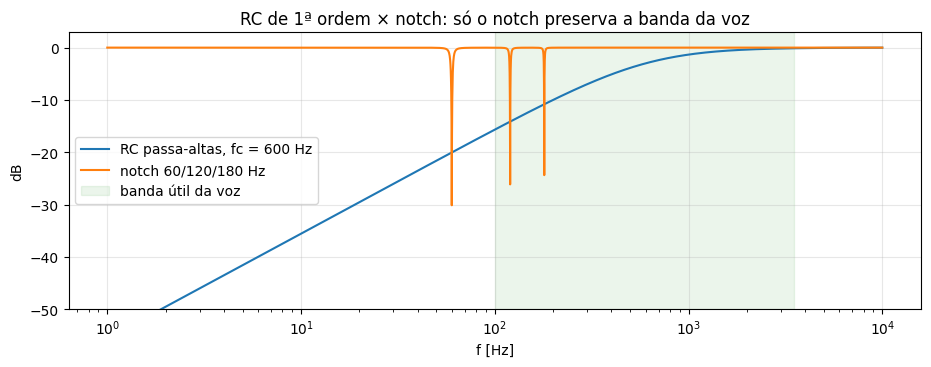

In [12]:
fr2 = np.logspace(0, 4, 3000)
fc_hp = 600
_, h_hp = signal.freqs([1/(2*np.pi*fc_hp), 0], [1/(2*np.pi*fc_hp), 1], worN=2*np.pi*fr2)
plt.semilogx(fr2, 20*np.log10(np.abs(h_hp)), label=f"RC passa-altas, fc = {fc_hp} Hz")
plt.semilogx(fr2, 20*np.log10(np.abs(H_total(1j*2*np.pi*fr2))), label="notch 60/120/180 Hz")
plt.axvspan(100, 3500, color="g", alpha=0.08, label="banda útil da voz")
plt.ylim(-50, 3); plt.xlabel("f [Hz]"); plt.ylabel("dB"); plt.legend()
plt.title("RC de 1ª ordem × notch: só o notch preserva a banda da voz"); plt.show()

## 4.2 Função de transferência pela Transformada de Laplace

Considere um notch passivo ou ativo (por exemplo, um circuito RLC). A relação entre entrada e saída é a EDO

$$y'' + \frac{\omega_0}{Q}\,y' + \omega_0^2\,y = x'' + \omega_0^2\,x$$

Aplicando $\mathcal{L}$ com condições iniciais nulas ($\mathcal{L}\{y''\} = s^2Y(s)$, $\mathcal{L}\{y'\} = sY(s)$):

$$\left(s^2 + \frac{\omega_0}{Q}s + \omega_0^2\right)Y(s) = \left(s^2 + \omega_0^2\right)X(s) \;\Rightarrow\; H(s) = \frac{Y(s)}{X(s)} = \frac{s^2 + \omega_0^2}{s^2 + \frac{\omega_0}{Q}s + \omega_0^2}$$

A seguir, o `sympy` refaz esse passo simbolicamente, encontra os polos e zeros e calcula a **resposta ao impulso** $h(t) = \mathcal{L}^{-1}\{H(s)\}$.

In [13]:
s, tt = sp.symbols("s t")
w0, Qs = sp.symbols("omega_0 Q", positive=True)
Xs, Ys = sp.symbols("X Y")

# EDO transformada → H(s)
eq = sp.Eq((s**2 + w0/Qs*s + w0**2)*Ys, (s**2 + w0**2)*Xs)
H_sym = sp.simplify(sp.solve(eq, Ys)[0] / Xs)
print("H(s) ="); display(H_sym)

zeros_sym = sp.solve(sp.numer(H_sym), s)
polos_sym = sp.solve(sp.denom(H_sym), s)
print("Zeros:"); display(zeros_sym)
print("Polos:"); display(polos_sym)

# Resposta ao impulso: H(s) = 1 − (ω0/Q)·s/(s² + (ω0/Q)s + ω0²)
alpha = w0/(2*Qs)
wd = sp.sqrt(w0**2 - alpha**2)
parte_propria = sp.simplify(sp.Integer(1) - H_sym)
print("1 − H(s) ="); display(parte_propria)

# Transformada inversa, com valores numéricos (60 Hz, Q = 30) para o sympy fechar a conta
vals = {w0: 2*sp.pi*60, Qs: 30}
h_prop = sp.inverse_laplace_transform(sp.apart(parte_propria.subs(vals), s), s, tt)
h_prop = sp.simplify(h_prop.rewrite(sp.cos)).subs(sp.Heaviside(tt), 1)   # vale para t > 0
print("h(t) = δ(t) − g(t)·u(t), com g(t) ="); display(h_prop)

H(s) =


Q*(omega_0**2 + s**2)/(Q*omega_0**2 + Q*s**2 + omega_0*s)

Zeros:


[-I*omega_0, I*omega_0]

Polos:


[omega_0*(sqrt(1 - 4*Q**2) - 1)/(2*Q), -omega_0*(sqrt(1 - 4*Q**2) + 1)/(2*Q)]

1 − H(s) =


omega_0*s/(Q*omega_0**2 + Q*s**2 + omega_0*s)

h(t) = δ(t) − g(t)·u(t), com g(t) =


-4*pi*(sqrt(3599)*sin(2*sqrt(3599)*pi*t) - 3599*cos(2*sqrt(3599)*pi*t))*exp(-2*pi*t)/3599

Máx. diferença sympy × forma fechada: 3.55e-15
α = ω0/(2Q) = 6.283 s⁻¹  →  τ = 1/α = 159 ms ;  ωd = 376.94 rad/s (59.992 Hz)


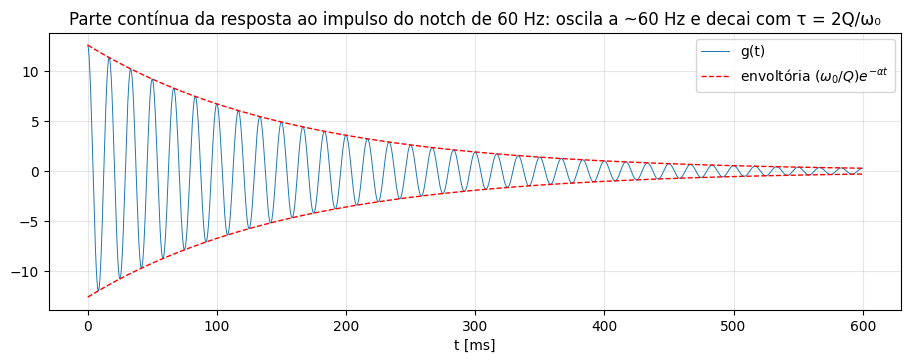

In [14]:
# Checagem da forma fechada: g(t) = (ω0/Q)·e^{−αt}[cos(ωd t) − (α/ωd) sin(ωd t)]·u(t)
w0n, Qn = 2*np.pi*60, 30
an = w0n/(2*Qn); wdn = np.sqrt(w0n**2 - an**2)
tg_ = np.linspace(0, 0.6, 6000)
g_fech = (w0n/Qn)*np.exp(-an*tg_)*(np.cos(wdn*tg_) - an/wdn*np.sin(wdn*tg_))
g_sym = sp.lambdify(tt, h_prop, "numpy")(tg_)
print(f"Máx. diferença sympy × forma fechada: {np.max(np.abs(np.real(g_sym) - g_fech)):.2e}")
print(f"α = ω0/(2Q) = {an:.3f} s⁻¹  →  τ = 1/α = {1000/an:.0f} ms ;  ωd = {wdn:.2f} rad/s ({wdn/2/np.pi:.3f} Hz)")

plt.plot(tg_*1000, g_fech, lw=0.7, label="g(t)")
plt.plot(tg_*1000, (w0n/Qn)*np.exp(-an*tg_), "r--", lw=1, label=r"envoltória $(\omega_0/Q)e^{-\alpha t}$")
plt.plot(tg_*1000, -(w0n/Qn)*np.exp(-an*tg_), "r--", lw=1)
plt.xlabel("t [ms]"); plt.title("Parte contínua da resposta ao impulso do notch de 60 Hz: oscila a ~60 Hz e decai com τ = 2Q/ω₀")
plt.legend(); plt.show()

## 4.3 Mapa de polos e zeros do filtro completo

 Polos (rad/s)                        |  Re   |  |p| / 2π   |  ζ = −Re/|p|
    -6.283    +376.939j      | <0  |   60.00 Hz |  0.0167
    -6.283    -376.939j      | <0  |   60.00 Hz |  0.0167
    -6.283    +753.956j      | <0  |  120.00 Hz |  0.0083
    -6.283    -753.956j      | <0  |  120.00 Hz |  0.0083
    -6.283   +1130.956j      | <0  |  180.00 Hz |  0.0056
    -6.283   -1130.956j      | <0  |  180.00 Hz |  0.0056

Zeros (rad/s): [-0. +376.99j  0. -376.99j -0. +753.98j  0. -753.98j -0.+1130.97j
  0.-1130.97j]

Todos os polos no semiplano esquerdo? True  →  sistema ESTÁVEL (BIBO)


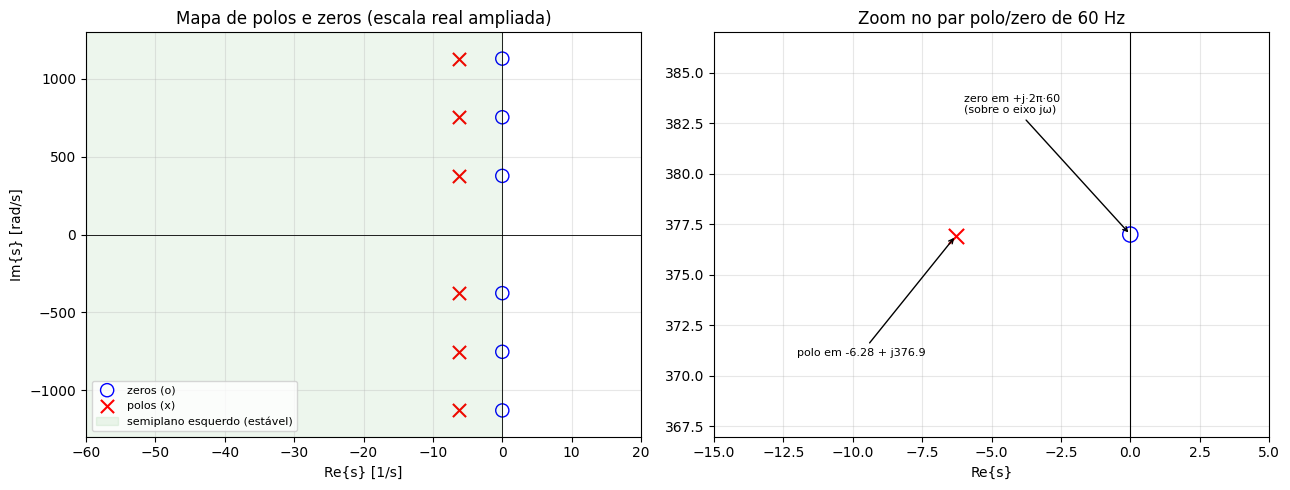

In [15]:
zeros_all, polos_all = [], []
for fk in FREQS_NOTCH:
    wk = 2*np.pi*fk
    zeros_all += list(np.roots([1, 0, wk**2]))
    polos_all += list(np.roots([1, wk/Q_de(fk), wk**2]))
zeros_all, polos_all = np.array(zeros_all), np.array(polos_all)

print(" Polos (rad/s)                        |  Re   |  |p| / 2π   |  ζ = −Re/|p|")
for p in polos_all:
    print(f" {p.real:9.3f} {p.imag:+11.3f}j      | {'<0' if p.real < 0 else '>=0'}  | {abs(p)/(2*np.pi):7.2f} Hz |  {-p.real/abs(p):.4f}")
print("\nZeros (rad/s):", np.round(zeros_all, 2))
estavel = np.all(polos_all.real < 0)
print(f"\nTodos os polos no semiplano esquerdo? {estavel}  →  sistema {'ESTÁVEL (BIBO)' if estavel else 'INSTÁVEL'}")

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
ax = axs[0]
ax.scatter(zeros_all.real, zeros_all.imag, s=90, facecolors="none", edgecolors="b", label="zeros (o)")
ax.scatter(polos_all.real, polos_all.imag, s=90, marker="x", color="r", label="polos (x)")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.axvspan(-60, 0, color="g", alpha=0.07, label="semiplano esquerdo (estável)")
ax.set_xlim(-60, 20); ax.set_ylim(-1300, 1300)
ax.set_xlabel("Re{s} [1/s]"); ax.set_ylabel("Im{s} [rad/s]"); ax.set_title("Mapa de polos e zeros (escala real ampliada)")
ax.legend(loc="lower left", fontsize=8)

ax = axs[1]                    # zoom em torno de +j·2π·60
wk = 2*np.pi*60
ax.scatter(zeros_all.real, zeros_all.imag, s=120, facecolors="none", edgecolors="b")
ax.scatter(polos_all.real, polos_all.imag, s=120, marker="x", color="r")
ax.axvline(0, color="k", lw=0.8)
ax.annotate("zero em +j·2π·60\n(sobre o eixo jω)", (0, wk), (-6, wk + 6), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.annotate(f"polo em {polos_all[0].real:.2f} + j{abs(polos_all[0].imag):.1f}", (polos_all[0].real, abs(polos_all[0].imag)),
            (-12, wk - 6), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-15, 5); ax.set_ylim(wk - 10, wk + 10)
ax.set_xlabel("Re{s}"); ax.set_title("Zoom no par polo/zero de 60 Hz")
plt.tight_layout(); plt.show()

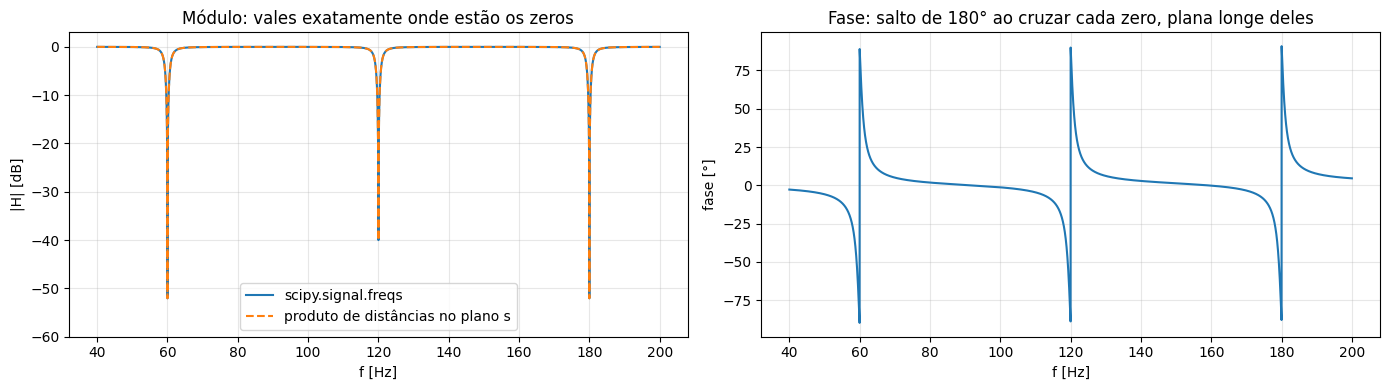

Notch    60 Hz: Q =   30 ; largura −3 dB = f/Q = 2.0 Hz ; distância polo→eixo jω = ω/2Q = 6.28 s⁻¹ ; ζ = 1/2Q = 0.0167
Notch   120 Hz: Q =   60 ; largura −3 dB = f/Q = 2.0 Hz ; distância polo→eixo jω = ω/2Q = 6.28 s⁻¹ ; ζ = 1/2Q = 0.0083
Notch   180 Hz: Q =   90 ; largura −3 dB = f/Q = 2.0 Hz ; distância polo→eixo jω = ω/2Q = 6.28 s⁻¹ ; ζ = 1/2Q = 0.0056


In [16]:
# Ligando a geometria do plano s à resposta em frequência: |H(jω)| = Π|jω − z| / Π|jω − p|
fr3 = np.linspace(40, 200, 8000)
jw = 1j*2*np.pi*fr3
H_geo = np.prod([jw - z for z in zeros_all], axis=0) / np.prod([jw - p for p in polos_all], axis=0)
w_b, h_b = signal.freqs(np.poly(zeros_all).real, np.poly(polos_all).real, worN=2*np.pi*fr3)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(fr3, 20*np.log10(np.abs(h_b)), label="scipy.signal.freqs")
axs[0].plot(fr3, 20*np.log10(np.abs(H_geo)), "--", label="produto de distâncias no plano s")
axs[0].set_ylim(-60, 3); axs[0].set_xlabel("f [Hz]"); axs[0].set_ylabel("|H| [dB]"); axs[0].legend()
axs[0].set_title("Módulo: vales exatamente onde estão os zeros")
axs[1].plot(fr3, np.degrees(np.angle(h_b)))
axs[1].set_xlabel("f [Hz]"); axs[1].set_ylabel("fase [°]")
axs[1].set_title("Fase: salto de 180° ao cruzar cada zero, plana longe deles")
plt.tight_layout(); plt.show()

for fk in FREQS_NOTCH:
    Qk = Q_de(fk)
    print(f"Notch {fk:5.0f} Hz: Q = {Qk:4.0f} ; largura −3 dB = f/Q = {fk/Qk:.1f} Hz ; "
          f"distância polo→eixo jω = ω/2Q = {2*np.pi*fk/(2*Qk):.2f} s⁻¹ ; ζ = 1/2Q = {1/(2*Qk):.4f}")

### Interpretação — Etapa 4

- **Função de transferência.** A Transformada de Laplace transforma a EDO do circuito em uma razão de polinômios. Cada notch é
$$H_k(s) = \frac{s^2 + \omega_k^2}{s^2 + (\omega_k/Q)s + \omega_k^2},$$
e o filtro completo tem **6 zeros e 6 polos**.

- **Onde estão os zeros.** Estão **sobre o eixo $j\omega$**, em $\pm j\,2\pi\cdot 60$, $\pm j\,2\pi\cdot 120$ e $\pm j\,2\pi\cdot 180$. Quando $s = j\omega$ passa por um zero, o numerador de $H$ se anula, o que explica a atenuação "infinita" medida nas raias da Etapa 3.

- **Onde estão os polos.** São pares complexos conjugados **logo à esquerda** de cada zero:
$$p = -\frac{\omega_k}{2Q} \pm j\,\omega_k\sqrt{1 - \frac{1}{4Q^2}}$$
Como $Q_k = f_k/2$, a distância até o eixo é $\omega_k/2Q_k = \pi \cdot 2 \approx 6{,}28\ \text{s}^{-1}$ **para os três pares**: os polos formam uma coluna vertical em $\text{Re}\{s\} = -6{,}28$. O amortecimento é baixíssimo ($\zeta = 1/2Q_k$ entre 0,017 e 0,006).
  - **Longe do notch:** o polo e o zero estão praticamente à mesma distância de $j\omega$, então as distâncias se cancelam e $|H| \approx 1$. A voz passa intacta.
  - **Perto do notch:** o zero "puxa" o módulo para zero. O polo vizinho limita a largura do vale a $\omega_k/Q_k$ (2 Hz). O gráfico do produto de distâncias reproduz exatamente a curva do `scipy`.

- **Estabilidade.** Todos os polos têm **parte real negativa** (semiplano esquerdo), então o sistema é **BIBO-estável**. A resposta ao impulso confirma isso: $h(t) = \delta(t) - g(t)$, e $g(t)$ decai como $e^{-\alpha t}$, com $\alpha = \omega_0/2Q = \pi \cdot BW$. Na versão digital, os polos equivalentes ficaram dentro do círculo unitário.

- **Conexão com as Etapas 2 e 3 (a mesma história em duas linguagens).**

| Plano s (Laplace) | Domínio da frequência (Fourier) | Domínio do tempo |
|---|---|---|
| Zeros em $\pm j\omega_k$ | Vales profundos em 60/120/180 Hz, exatamente onde o espectro da Etapa 2 mostrava as raias do zumbido | A senoide da rede é cancelada |
| Polos a uma distância $\omega_k/2Q_k = 6{,}28$ do eixo | Largura do vale $= f_k/Q_k = 2$ Hz, que poupa o 2º harmônico da voz perto de 180–190 Hz | Constante de tempo $\tau = 2Q_k/\omega_k \approx 160$ ms: é o transitório de ~0,8 s visto no início da versão causal (seção 3.3) |
| Polos no semiplano esquerdo | $H(j\omega)$ existe e é finita | $h(t)$ decai, então o sistema é estável |

- **Compromisso de projeto.** Aumentar $Q$ aproxima os polos do eixo $j\omega$. Isso deixa o notch mais estreito (menos voz afetada), mas o transitório fica mais longo e o filtro fica mais sensível a variações da frequência da rede (que oscila levemente em torno de 60 Hz). A largura de 2 Hz equilibra os dois lados.

---
# Conclusão

1. **Etapa 1.** Senos e cossenos formam uma base ortogonal capaz de representar até funções descontínuas. O preço é o fenômeno de Gibbs, com overshoot fixo de cerca de 9% no salto.
2. **Etapa 2.** Pela FFT, o zumbido, que no tempo é uma ondulação escondida sob a voz, virou três raias estreitas e fáceis de localizar. Isso só foi possível com a taxa de amostragem correta, respeitando Nyquist.
3. **Etapa 3.** Com essa informação foi projetado um notch em cascata. Aplicado como $Y = H(j\omega)X$ e reconstruído pela Transformada Inversa, ele remove o zumbido e eleva o SNR em dezenas de dB, com resultado audível no antes/depois.
4. **Etapa 4.** A Transformada de Laplace dá a explicação estrutural: zeros sobre o eixo $j\omega$ produzem a rejeição, polos próximos e no semiplano esquerdo definem a largura do vale, o transitório e a estabilidade.

**Arquivos gerados** (pasta `audios/`): `voz_limpa.wav`, `voz_com_zumbido.wav`, `voz_filtrada.wav`, `voz_filtrada_fase_zero.wav` e `voz_filtrada_tempo_real.wav`.